# 19 · Descriptors, Matching and Geometric Validation

LRT4012 Robot Vision · Fall 2026


## Correspondences need appearance and geometry

ORB with `WTA_K=2` uses Hamming distance; `WTA_K=3` or `4` requires Hamming2. SIFT descriptors use Euclidean distance. A ratio test accepts a candidate when $d_1<\rho d_2$, where $d_1,d_2$ are the distances to the nearest and second-nearest descriptors and $\rho=0.75$ is the selected ratio.

$$e_i=\|\pi(H_{\mathrm{true}}\tilde p_i)-q_i\|_2.$$

$p_i,q_i$ are matched 2D pixel positions, $\tilde p_i=(x_i,y_i,1)^T$ is the homogeneous source position, $H_{\mathrm{true}}$ is the known synthetic transformation, and $\pi(a,b,c)=(a/c,b/c)$ converts to Euclidean coordinates. $e_i$ is the transfer error in pixels. RANSAC estimates a separate homography from at least four nondegenerate correspondences; its inlier count is not independent ground truth.

A homography models a planar scene, or a camera rotation about its optical center under the pinhole model. It does not generally describe translation through a nonplanar scene.


In [3]:
from pathlib import Path
import os, time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_repository():
    candidates = []
    if os.environ.get('VISION_ROBOTICA_REPO'):
        candidates.append(Path(os.environ['VISION_ROBOTICA_REPO']).expanduser())
    candidates += [Path.cwd(), *Path.cwd().parents]
    for root in candidates:
        if (root / 'requirements.txt').is_file() and (root / 'imagenes').is_dir():
            return root.resolve()
    raise FileNotFoundError('Open Jupyter inside the course repository, or set VISION_ROBOTICA_REPO to its root.')

REPO = find_repository()
IMAGE_DIR = REPO / 'imagenes'  # Read-only official resources.
# Save your own notebook and generated images in student_work/ and student_work/imagenes/.
cv2.setRNGSeed(4012)
cv2.setNumThreads(1)
rng = np.random.default_rng(4012)
plt.rcParams.update({'figure.dpi':100, 'font.size':10})

def load_image(name, max_side=640):
    image = cv2.imread(str(IMAGE_DIR / name), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f'Official resource could not be read: {name}')
    h, w = image.shape[:2]
    if max(h, w) > max_side:
        scale = max_side / max(h, w)
        image = cv2.resize(image, (round(w*scale), round(h*scale)), interpolation=cv2.INTER_AREA)
    return image

def gray(image): return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

def panels(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(4*len(images), 3.5), squeeze=False)
    for ax, im, title in zip(axes[0], images, titles):
        if im.ndim == 3:
            ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(im, cmap='gray', vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis('off')
    fig.tight_layout()
    plt.show()

def timed_ms(fn, repetitions=30):
    fn()  # Warm-up.
    times = []
    for _ in range(repetitions):
        start = time.perf_counter()
        fn()
        times.append((time.perf_counter()-start)*1000)
    return float(np.median(times))

def mask_metrics(prediction, reference):
    a, b = prediction.astype(bool), reference.astype(bool)
    tp = int(np.count_nonzero(a & b))
    fp = int(np.count_nonzero(a & ~b))
    fn = int(np.count_nonzero(~a & b))
    return {'IoU': tp/(tp+fp+fn) if tp+fp+fn else 1.0,
            'precision': tp/(tp+fp) if tp+fp else np.nan,
            'recall': tp/(tp+fn) if tp+fn else np.nan,
            'F1': 2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 1.0}


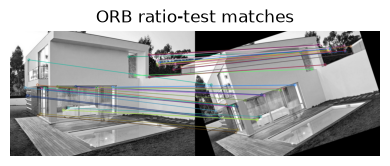

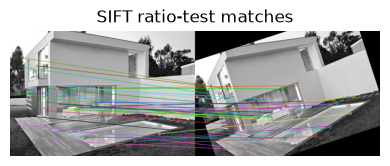

,method,ratio_matches,fraction_within_3px_known_H,median_error_px_known_H,RANSAC_inliers
0,ORB,311,0.936,0.883,287
1,SIFT,391,0.977,0.160,382


In [4]:
image=load_image('casa.png'); g=gray(image); h,w=g.shape
affine=cv2.getRotationMatrix2D((w/2,h/2),18,0.95)
known_H=np.vstack([affine,[0,0,1]])
view=cv2.warpPerspective(g,known_H,(w,h),borderMode=cv2.BORDER_CONSTANT)
rows=[]
for name,detector,norm in [('ORB',cv2.ORB_create(nfeatures=800),cv2.NORM_HAMMING),('SIFT',cv2.SIFT_create(nfeatures=800),cv2.NORM_L2)]:
    ka,da=detector.detectAndCompute(g,None);kb,db=detector.detectAndCompute(view,None)
    matches=[]
    if da is not None and db is not None and len(db)>=2:
        neighbors=cv2.BFMatcher(norm).knnMatch(da,db,k=2)
        matches=[pair[0] for pair in neighbors if len(pair)==2 and pair[0].distance<0.75*pair[1].distance]
    H=None; inlier_mask=None; error=np.array([])
    if matches:
        pa=np.float32([ka[m.queryIdx].pt for m in matches]).reshape(-1,1,2)
        pb=np.float32([kb[m.trainIdx].pt for m in matches]).reshape(-1,1,2)
        predicted=cv2.perspectiveTransform(pa,known_H)
        error=np.linalg.norm(predicted-pb,axis=2).ravel()
        if len(matches)>=4:
            H,inlier_mask=cv2.findHomography(pa,pb,cv2.RANSAC,3.0)
    rows.append({'method':name,'ratio_matches':len(matches),
                 'fraction_within_3px_known_H':float(np.mean(error<=3)) if len(error) else np.nan,
                 'median_error_px_known_H':float(np.median(error)) if len(error) else np.nan,
                 'RANSAC_inliers':int(inlier_mask.sum()) if inlier_mask is not None else 0})
    drawing=cv2.drawMatches(g,ka,view,kb,sorted(matches,key=lambda m:m.distance)[:40],None,
                            flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    panels([drawing],[name+' ratio-test matches'])
display(pd.DataFrame(rows).round(3))


## Robotic interpretation

Compare descriptor matching with geometric correctness. Explain failure on repeated textures. Identify why a homography cannot recover general robot motion through a 3D environment.


## References

- [OpenCV: Harris](https://docs.opencv.org/4.x/dc/d0d/tutorial_py_features_harris.html)
- [OpenCV: ORB parameters](https://docs.opencv.org/4.13.0/db/d95/classcv_1_1ORB.html)
- [OpenCV: SIFT](https://docs.opencv.org/4.x/da/df5/tutorial_py_sift_intro.html)
- [OpenCV: feature matching](https://docs.opencv.org/4.x/dc/dc3/tutorial_py_matcher.html)
